### Cell 1: load and reshape

In [1]:
import warnings
import numpy as np
import pandas as pd
from google.cloud import bigquery

warnings.filterwarnings("ignore")   # statsmodels prints many fit warnings

client = bigquery.Client(project="supply-chain-analytics-510105")
long = client.query(
    "select series, week_start, orders "
    "from `supply-chain-analytics-510105.dbt_dev_ml.ml_weekly_demand`"
).to_dataframe()
long["week_start"] = pd.to_datetime(long["week_start"])

# one column per series, one row per week; missing weeks = 0 orders
weeks = pd.date_range("2017-01-02", "2018-08-20", freq="W-MON")
y = (long.pivot(index="week_start", columns="series", values="orders")
         .reindex(weeks)
         .fillna(0))
print(y.shape)
y.tail()

(86, 6)


series,all_orders,bed_bath_table,computers_accessories,furniture_decor,health_beauty,sports_leisure
2018-07-23,1634,125,103,99,142,121
2018-07-30,2030,166,134,106,220,132
2018-08-06,1961,161,112,111,240,116
2018-08-13,1852,180,117,103,217,136
2018-08-20,1058,88,53,52,137,74


###  Cell 2: look at the data first

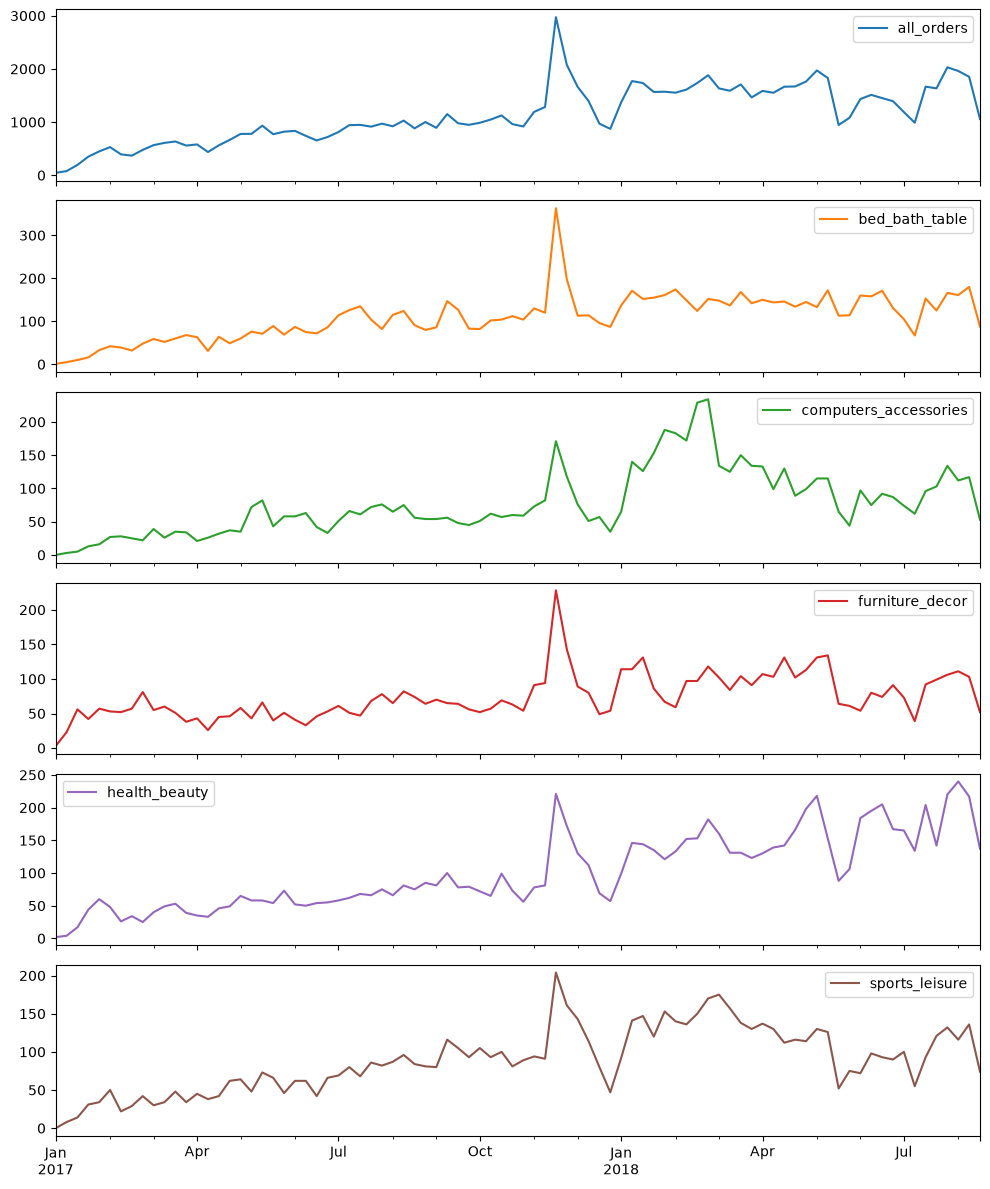

In [2]:
import matplotlib.pyplot as plt

y.plot(subplots=True, figsize=(10, 12), sharex=True)
plt.tight_layout()

### Cell 3: the forecasting methods

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Each method gets the history up to the forecast origin and returns the forecast h weeks ahead.

def naive(hist, h):
    return hist.iloc[-1]                          # "same as last week"

def moving_avg_4(hist, h):
    return hist.iloc[-4:].mean()                  # "average of the last 4 weeks"

def same_week_last_year(hist, h):
    target = len(hist) - 1 + h                    # position of the week being forecast
    return hist.iloc[target - 52]                 # the same week one year earlier

def ets_damped(hist, h):
    model = ExponentialSmoothing(hist, trend="add", damped_trend=True).fit()
    return max(model.forecast(h).iloc[-1], 0)     # orders can't be negative

methods = {
    "naive (last week)": naive,
    "4-week average": moving_avg_4,
    "same week last year": same_week_last_year,
    "ETS (damped trend)": ets_damped,
}

### Cell 4: walk-forward evaluation

In [4]:
def walk_forward(series, method, h, n_test=26):
    """For each of the last n_test weeks, forecast it using only data up to h weeks before."""
    preds, actuals = [], []
    for t in range(len(series) - n_test, len(series)):
        hist = series.iloc[: t - h + 1]           # everything known at the forecast origin
        preds.append(method(hist, h))
        actuals.append(series.iloc[t])
    return np.array(preds), np.array(actuals)

def wape(actual, pred):
    return np.abs(actual - pred).sum() / actual.sum()

rows = []
for series_name in y.columns:
    for h in (1, 4):
        for method_name, method in methods.items():
            p, a = walk_forward(y[series_name], method, h)
            rows.append({"series": series_name, "horizon": f"{h}w", "method": method_name,
                         "wape": round(wape(a, p), 3)})

results = pd.DataFrame(rows)
table = results.pivot_table(index=["series", "horizon"], columns="method", values="wape")
table

method                         4-week average  ETS (damped trend)  \
series                horizon                                       
all_orders            1w                0.162               0.138   
                      4w                0.173               0.219   
bed_bath_table        1w                0.171               0.159   
                      4w                0.154               0.165   
computers_accessories 1w                0.250               0.236   
                      4w                0.329               0.360   
furniture_decor       1w                0.230               0.217   
                      4w                0.260               0.297   
health_beauty         1w                0.233               0.189   
                      4w                0.205               0.292   
sports_leisure        1w                0.198               0.174   
                      4w                0.237               0.266   

method                         naive (last week)  same week last year  
series                horizon                                          
all_orders            1w                   0.138                0.518  
                      4w                   0.218                0.518  
bed_bath_table        1w                   0.187                0.474  
                      4w                   0.202                0.474  
computers_accessories 1w                   0.233                0.553  
                      4w                   0.333                0.553  
furniture_decor       1w                   0.210                0.449  
                      4w                   0.310                0.449  
health_beauty         1w                   0.195                0.664  
                      4w                   0.269                0.664  
sports_leisure        1w                   0.167                0.504  
                      4w                   0.271                0.504

### Cell 5: two more methods, with a select/report split

In [5]:
def ses(hist, h):
    model = ExponentialSmoothing(hist, trend=None).fit()
    return max(model.forecast(h).iloc[-1], 0)

def avg_of_ses_and_ma4(hist, h):
    return (ses(hist, h) + moving_avg_4(hist, h)) / 2

methods2 = {
    "4-week average": moving_avg_4,
    "ETS (damped trend)": ets_damped,
    "SES (no trend)": ses,
    "SES + 4-week avg": avg_of_ses_and_ma4,
}

rows = []
for series_name in y.columns:
    for h in (1, 4):
        for method_name, method in methods2.items():
            p, a = walk_forward(y[series_name], method, h)
            rows.append({
                "series": series_name, "horizon": f"{h}w", "method": method_name,
                "wape_select": wape(a[:13], p[:13]),   # Mar-May 2018: used to choose
                "wape_report": wape(a[13:], p[13:]),   # Jun-Aug 2018: reported only
            })
res = pd.DataFrame(rows)

# 1) choose the method with the lowest average error on the SELECT weeks, per horizon
choice = (res.groupby(["horizon", "method"])["wape_select"].mean()
             .round(3).unstack("method"))
print("Average WAPE on selection weeks (Mar-May):")
display(choice)

# 2) report every method on the untouched REPORT weeks
report = res.pivot_table(index=["series", "horizon"], columns="method",
                         values="wape_report").round(3)
print("WAPE on report weeks (Jun-Aug):")
display(report)

Average WAPE on selection weeks (Mar-May):


method,4-week average,ETS (damped trend),SES (no trend),SES + 4-week avg
horizon,,,,
1w,0.160,0.155,0.144,0.146
4w,0.196,0.215,0.195,0.192


WAPE on report weeks (Jun-Aug):


method                         4-week average  ETS (damped trend)  \
series                horizon                                       
all_orders            1w                0.222               0.166   
                      4w                0.235               0.314   
bed_bath_table        1w                0.271               0.215   
                      4w                0.218               0.209   
computers_accessories 1w                0.271               0.260   
                      4w                0.272               0.353   
furniture_decor       1w                0.318               0.273   
                      4w                0.387               0.439   
health_beauty         1w                0.247               0.208   
                      4w                0.189               0.311   
sports_leisure        1w                0.255               0.204   
                      4w                0.277               0.341   

method                         SES (no trend)  SES + 4-week avg  
series                horizon                                    
all_orders            1w                0.162             0.186  
                      4w                0.308             0.259  
bed_bath_table        1w                0.243             0.256  
                      4w                0.221             0.219  
computers_accessories 1w                0.260             0.252  
                      4w                0.350             0.305  
furniture_decor       1w                0.267             0.291  
                      4w                0.433             0.399  
health_beauty         1w                0.228             0.223  
                      4w                0.272             0.220  
sports_leisure        1w                0.207             0.215  
                      4w                0.343             0.296

### Cell 6: save the results

In [6]:
from pathlib import Path
out = Path("outputs"); out.mkdir(exist_ok=True)
res.to_csv(out / "demand_forecast_results.csv", index=False)